SECURESENSE - RANDOM FOREST

Loading training data...
Loading testing data...

Training shape: (1785012, 70)
Testing shape : (446254, 70)

Number of features: 69

Training class distribution:
BinaryLabel
0    1516035
1     268977
Name: count, dtype: int64

Testing class distribution:
BinaryLabel
0    379009
1     67245
Name: count, dtype: int64

TRAINING RANDOM FOREST

Training completed in 431.99 seconds

Generating predictions...

RANDOM FOREST RESULTS

Accuracy  : 0.999018 (99.90%)
Precision : 0.995755 (99.58%)
Recall    : 0.997740 (99.77%)
F1 Score  : 0.996746 (99.67%)
ROC-AUC   : 0.999985 (100.00%)
PR-AUC    : 0.999925 (99.99%)
Train Time: 431.99 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      BENIGN     0.9996    0.9992    0.9994    379009
      ATTACK     0.9958    0.9977    0.9967     67245

    accuracy                         0.9990    446254
   macro avg     0.9977    0.9985    0.9981    446254
weighted avg     0.9990    0.9990    

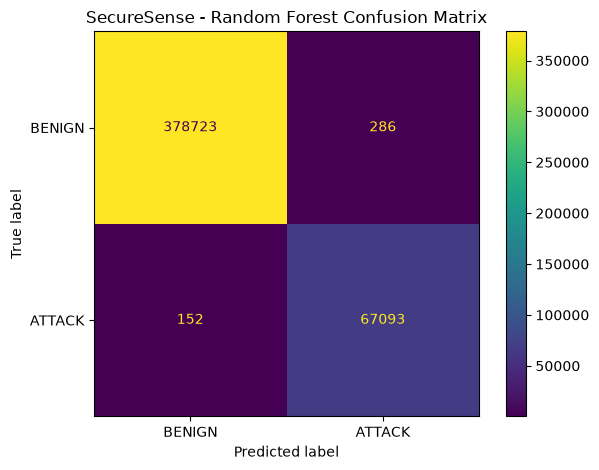

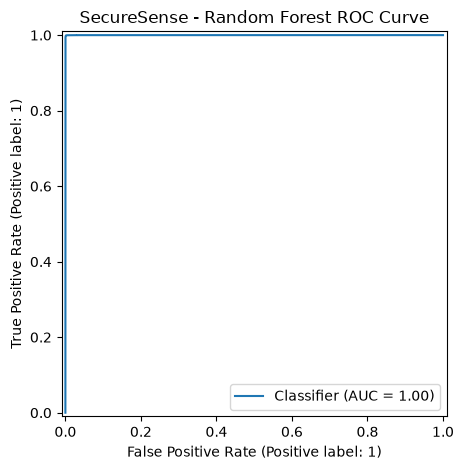

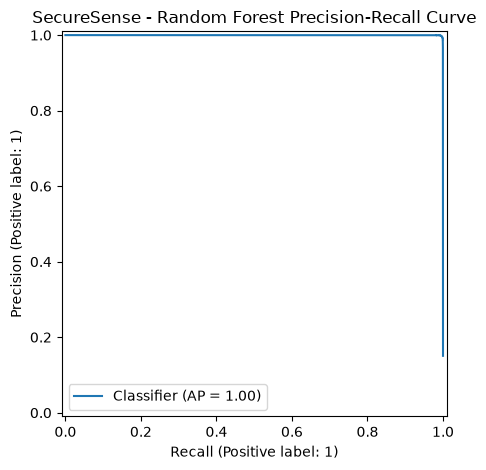


TOP 20 IMPORTANT FEATURES
                 Feature  Importance
   Bwd Packet Length Std    0.094253
  Packet Length Variance    0.080761
    Avg Bwd Segment Size    0.068428
       Packet Length Std    0.067350
  Bwd Packet Length Mean    0.062426
   Bwd Packet Length Max    0.049383
         Avg Packet Size    0.047307
      Packet Length Mean    0.040682
       Subflow Bwd Bytes    0.036595
Bwd Packets Length Total    0.032767
       Packet Length Max    0.028225
       Fwd Header Length    0.025572
           Bwd Packets/s    0.024994
           Fwd IAT Total    0.020458
       Total Fwd Packets    0.019990
     Subflow Bwd Packets    0.016997
   Fwd Packet Length Max    0.016053
      Init Fwd Win Bytes    0.015143
            Fwd IAT Mean    0.014518
  Total Backward Packets    0.014070


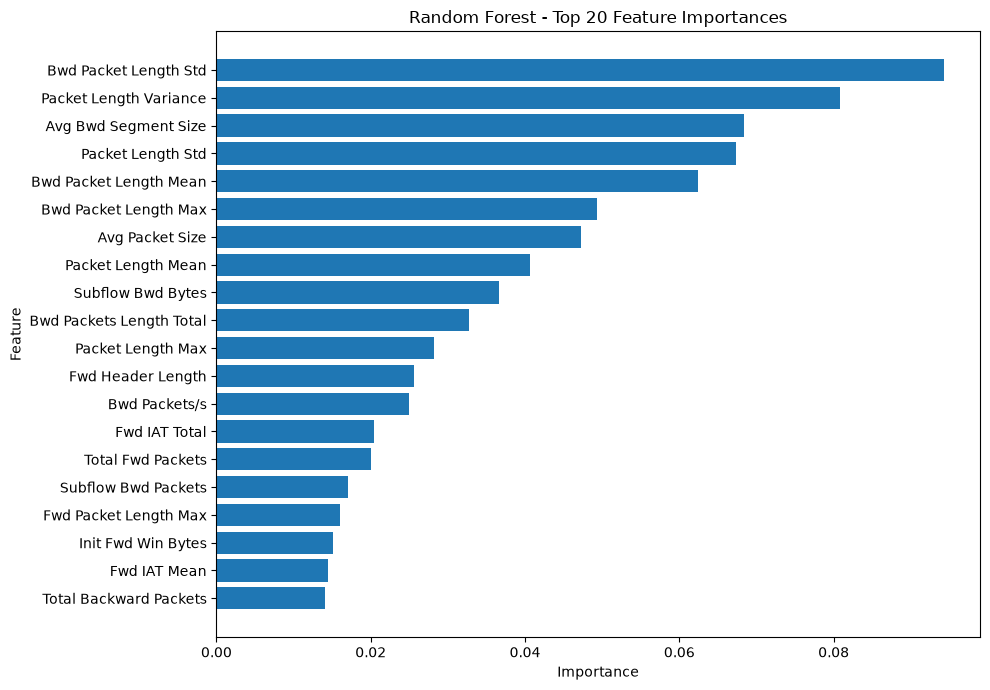


Model saved to: ../models\random_forest.pkl
Metrics saved to: ../results\random_forest_metrics.csv
Feature importance saved to: ../results\random_forest_feature_importance.csv

RANDOM FOREST COMPLETED SUCCESSFULLY

Final Metrics:
        Model  Accuracy  Precision  Recall       F1  ROC_AUC   PR_AUC  Training_Time_Seconds
Random Forest  0.999018   0.995755 0.99774 0.996746 0.999985 0.999925             431.994975

Files created:
  ✓ ../models\random_forest.pkl
  ✓ ../results\random_forest_metrics.csv
  ✓ ../results\random_forest_feature_importance.csv

Next model: HistGradientBoosting


In [1]:
# ============================================================
# SECURESENSE - RANDOM FOREST
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# 1. PATHS
# ============================================================

TRAIN_PATH = "../data/splits/train.parquet"
TEST_PATH = "../data/splits/test.parquet"

MODEL_DIR = "../models"
RESULT_DIR = "../results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ============================================================
# 2. LOAD DATA
# ============================================================

print("=" * 80)
print("SECURESENSE - RANDOM FOREST")
print("=" * 80)

print("\nLoading training data...")
train_df = pd.read_parquet(TRAIN_PATH)

print("Loading testing data...")
test_df = pd.read_parquet(TEST_PATH)

print(f"\nTraining shape: {train_df.shape}")
print(f"Testing shape : {test_df.shape}")

# ============================================================
# 3. SEPARATE FEATURES AND TARGET
# ============================================================

TARGET = "BinaryLabel"

X_train = train_df.drop(columns=[TARGET])
X_test = test_df.drop(columns=[TARGET])

y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

print(f"\nNumber of features: {X_train.shape[1]}")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

# ============================================================
# 4. RANDOM FOREST MODEL
# ============================================================

print("\n" + "=" * 80)
print("TRAINING RANDOM FOREST")
print("=" * 80)

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"\nTraining completed in {training_time:.2f} seconds")

# ============================================================
# 5. PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# ============================================================
# 6. METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("\n" + "=" * 80)
print("RANDOM FOREST RESULTS")
print("=" * 80)

print(f"\nAccuracy  : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.6f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.6f} ({recall * 100:.2f}%)")
print(f"F1 Score  : {f1:.6f} ({f1 * 100:.2f}%)")
print(f"ROC-AUC   : {roc_auc:.6f} ({roc_auc * 100:.2f}%)")
print(f"PR-AUC    : {pr_auc:.6f} ({pr_auc * 100:.2f}%)")
print(f"Train Time: {training_time:.2f} seconds")

# ============================================================
# 7. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 8. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\n" + "=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot()
plt.title("SecureSense - Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# 9. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("SecureSense - Random Forest ROC Curve")
plt.tight_layout()
plt.show()

# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("SecureSense - Random Forest Precision-Recall Curve")
plt.tight_layout()
plt.show()

# ============================================================
# 11. FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n" + "=" * 80)
print("TOP 20 IMPORTANT FEATURES")
print("=" * 80)

print(feature_importance.head(20).to_string(index=False))

# Plot top 20 features
top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 20 Feature Importances")
plt.tight_layout()
plt.show()

# ============================================================
# 12. SAVE MODEL
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    "random_forest.pkl"
)

joblib.dump(model, model_path)

print(f"\nModel saved to: {model_path}")

# ============================================================
# 13. SAVE METRICS
# ============================================================

metrics = pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}])

metrics_path = os.path.join(
    RESULT_DIR,
    "random_forest_metrics.csv"
)

metrics.to_csv(metrics_path, index=False)

print(f"Metrics saved to: {metrics_path}")

# ============================================================
# 14. SAVE FEATURE IMPORTANCE
# ============================================================

importance_path = os.path.join(
    RESULT_DIR,
    "random_forest_feature_importance.csv"
)

feature_importance.to_csv(
    importance_path,
    index=False
)

print(f"Feature importance saved to: {importance_path}")

# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("RANDOM FOREST COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nFinal Metrics:")
print(metrics.to_string(index=False))

print("\nFiles created:")
print(f"  ✓ {model_path}")
print(f"  ✓ {metrics_path}")
print(f"  ✓ {importance_path}")

print("\nNext model: HistGradientBoosting")

SECURESENSE - FINAL GROUP-AWARE LOGISTIC REGRESSION

Training shape: (1555942, 69)
Testing shape : (675324, 69)

Scaling features...

Training Logistic Regression...
Training time: 66.08 seconds

FINAL LOGISTIC REGRESSION RESULTS
Accuracy  : 0.918550 (91.86%)
Precision : 0.848338 (84.83%)
Recall    : 0.694464 (69.45%)
F1 Score  : 0.763727 (76.37%)
ROC-AUC   : 0.981506 (98.15%)
PR-AUC    : 0.922156 (92.22%)
Training Time: 66.08 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      BENIGN     0.9314    0.9710    0.9508    547313
      ATTACK     0.8483    0.6945    0.7637    128011

    accuracy                         0.9186    675324
   macro avg     0.8899    0.8327    0.8573    675324
weighted avg     0.9157    0.9186    0.9153    675324


Confusion Matrix:
[[531420  15893]
 [ 39112  88899]]


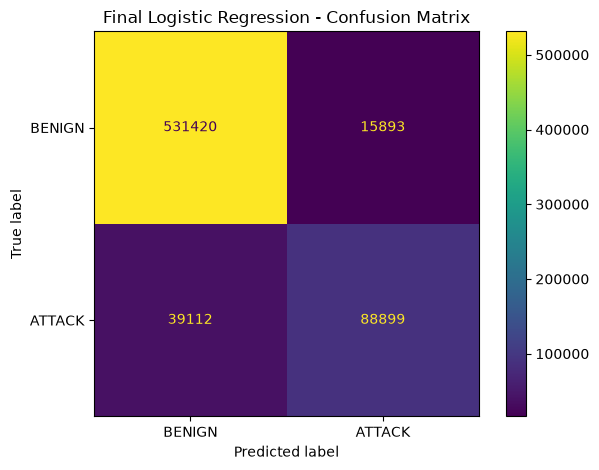

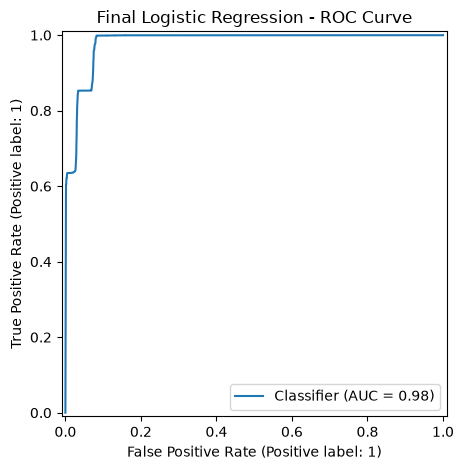

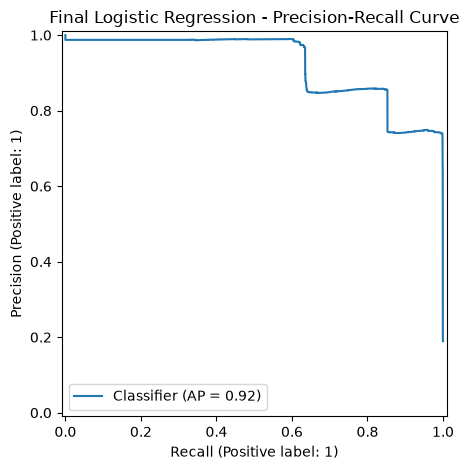


FINAL LOGISTIC REGRESSION COMPLETED

Model saved  : W:\FinalYearProject\SecureSense_Project\models\final_logistic_regression.pkl
Scaler saved : W:\FinalYearProject\SecureSense_Project\models\final_logistic_regression_scaler.pkl
Metrics saved: W:\FinalYearProject\SecureSense_Project\results\final_logistic_regression_metrics.csv

✓ Evaluation performed on completely unseen source files.


In [7]:
# ============================================================
# SECURESENSE - FINAL GROUP-AWARE LOGISTIC REGRESSION
# ============================================================

import os
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# PATHS
# ============================================================
PROJECT_ROOT = r"W:\FinalYearProject\SecureSense_Project"

TRAIN_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\train.parquet"

TEST_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\test.parquet"



MODEL_DIR = os.path.join(PROJECT_ROOT, "models")
RESULT_DIR = os.path.join(PROJECT_ROOT, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ============================================================
# LOAD
# ============================================================

print("=" * 80)
print("SECURESENSE - FINAL GROUP-AWARE LOGISTIC REGRESSION")
print("=" * 80)

train_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

TARGET = "BinaryLabel"

X_train = train_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

X_test = test_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

y_train = train_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

y_test = test_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

print(f"\nTraining shape: {X_train.shape}")
print(f"Testing shape : {X_test.shape}")

# ============================================================
# SCALE - FIT ONLY ON TRAIN
# ============================================================

print("\nScaling features...")

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================
# TRAIN
# ============================================================

print("\nTraining Logistic Regression...")

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

start = time.time()

model.fit(X_train_scaled, y_train)

training_time = time.time() - start

print(f"Training time: {training_time:.2f} seconds")

# ============================================================
# PREDICTION
# ============================================================

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("\n" + "=" * 80)
print("FINAL LOGISTIC REGRESSION RESULTS")
print("=" * 80)

print(f"Accuracy  : {accuracy:.6f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.6f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.6f} ({recall*100:.2f}%)")
print(f"F1 Score  : {f1:.6f} ({f1*100:.2f}%)")
print(f"ROC-AUC   : {roc_auc:.6f} ({roc_auc*100:.2f}%)")
print(f"PR-AUC    : {pr_auc:.6f} ({pr_auc*100:.2f}%)")
print(f"Training Time: {training_time:.2f} seconds")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot()

plt.title("Final Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Final Logistic Regression - ROC Curve")
plt.tight_layout()
plt.show()

# ============================================================
# PR CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("Final Logistic Regression - Precision-Recall Curve")
plt.tight_layout()
plt.show()

# ============================================================
# SAVE MODEL + SCALER
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    "final_logistic_regression.pkl"
)

scaler_path = os.path.join(
    MODEL_DIR,
    "final_logistic_regression_scaler.pkl"
)

joblib.dump(model, model_path)
joblib.dump(scaler, scaler_path)

# ============================================================
# SAVE METRICS
# ============================================================

metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Evaluation": "Final Group-Aware",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}])

metrics_path = os.path.join(
    RESULT_DIR,
    "final_logistic_regression_metrics.csv"
)

metrics.to_csv(metrics_path, index=False)

# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 80)
print("FINAL LOGISTIC REGRESSION COMPLETED")
print("=" * 80)

print(f"\nModel saved  : {model_path}")
print(f"Scaler saved : {scaler_path}")
print(f"Metrics saved: {metrics_path}")

print("\n✓ Evaluation performed on completely unseen source files.")

In [5]:
PROJECT_ROOT = r"W:\FinalYearProject\SecureSense_Project"

TRAIN_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\train.parquet"

TEST_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\test.parquet"

MODEL_DIR = os.path.join(PROJECT_ROOT, "models")
RESULT_DIR = os.path.join(PROJECT_ROOT, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("TRAIN exists:", os.path.exists(TRAIN_PATH))
print("TEST exists :", os.path.exists(TEST_PATH))

TRAIN exists: True
TEST exists : True


In [4]:
import os

PROJECT_ROOT = r"W:\FinalYearProject\SecureSense_Project"

print("Searching for final group split files...\n")

for root, dirs, files in os.walk(PROJECT_ROOT):
    for file in files:
        if file in ["train.parquet", "test.parquet"]:
            if "group" in root.lower():
                print(os.path.join(root, file))

Searching for final group split files...

W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\test.parquet
W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\train.parquet
